# mmb0-1b_smb1-1b_2p Analysis

- Creator: Sebastian Birk (sb75@sanger.ac.uk)
- Date of Creation: 21.02.2025
- Date of Last Modification: 27.02.2026 (by Sebastian Birk; sb75@sanger.ac.uk)

## 1.1 Load Libraries 

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append("../../utils")

In [3]:
import logging
import os
import warnings
import pickle
import random
from datetime import datetime

import anndata as ad
import torch
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import scib_metrics
import seaborn as sns
try:
    import squidpy as sq
except:
    import dask
    dask.config.set({"dataframe.query-planning": True})
    import dask.dataframe.dask_expr
    print("Could not import squidpy...")
    import rapids_singlecell as rsc
from datasets import load_from_disk
from sklearn.metrics.cluster import adjusted_rand_score, normalized_mutual_info_score
from sklearn.model_selection import train_test_split

from app.inference import infer
from app.training import train
from nichejepa.datasets import prepare_dataset
from nichejepa.utils.config import create_params_from_YAML_wandb_config
from nichejepa.utils.distributed import init_distributed
from nichejepa.utils.evaluation import clustering_metrics, classification_metrics

from analysis_utils import *

/nfs/team361/sb75/ENVS/rapids-singlecell-nichejepa/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Could not import squidpy...


2026-03-01 22:46:01 | [INFO] JAX version 0.8.1 available.
/nfs/team361/sb75/ENVS/rapids-singlecell-nichejepa/lib/python3.13/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution
/nfs/team361/sb75/ENVS/rapids-singlecell-nichejepa/lib/python3.13/site-packages/spatialdata/_core/query/relational_query.py:530: FutureWarning: functools.partial will be a method descriptor in future Python versions; wrap it in enum.member() if you want to preserve the old behavior
  left = partial(_left_join_spatialelement_table)
/nfs/team361/sb75/ENVS/rapids-singlecell-nichejepa/lib/python3.13/site-packages/spatialdata/_core/query/relational_query.py:531: FutureWarning: functools.partial will be a method descriptor i

## 1.2 Load Config/Params
All setup will be done in the config file. Please edit that file to continue.

In [4]:
# Set params
dataset = 'mmb0-1b_smb1-1b_2p'
tokenizer = 'cell_graph'
# load_timestamp = '29032025_080927_875' # gt_tiny
# load_timestamp = '03042025_224852_256' # gt_small
# load_timestamp = '27032025_163938_061' # gt_base
# load_timestamp = '03042025_224013_784' # gt_large
# load_timestamp = None
load_timestamp = '01032026_084053_474' # '27022026_084243_486'
model_type = 'test'
read_checkpoint = 'nichejepa-ep299.pth.tar' # 'nichejepa-ep1_6.pth.tar'

In [5]:
emb_layer = None
n_layer = 3
top_k = None
batch_size = 128
pin_memory = False
num_workers = 12
n_pcs = 0

In [6]:
model_config_folder_path = '/nfs/team361/sb75/nichejepa/configs/model'
artifacts_folder_path = '/nfs/team361/sb75/nichejepa-reproducibility/artifacts'
datasets_folder_path = '/lustre/scratch126/cellgen/lotfollahi/DATASETS'
token_dict_path = '/lustre/scratch126/cellgen/lotfollahi/DATASETS/tokenizer/token_dictionary_mus_musculus.pkl'

In [7]:
# Set up logger
rank=0
logging.basicConfig()
logger = logging.getLogger()
logger.setLevel(logging.INFO if rank == 0 else logging.ERROR)

In [8]:
# Load config
if not load_timestamp:
    params = create_params_from_YAML_wandb_config(f'{model_config_folder_path}/{dataset}_{model_type}.yaml',logger)
else:
    params = create_params_from_YAML_wandb_config(f'{artifacts_folder_path}/{dataset}/{load_timestamp}/params.yaml',logger)

if read_checkpoint:
    params['state']['read_checkpoint'] = read_checkpoint
if load_timestamp:
    params['state']['load_checkpoint'] = True

params

2026-03-01 22:46:29 | [INFO] Loaded parameters from YAML file.


{'data': {'batch_size': 256,
  'count_cell_norm_method': None,
  'count_count_norm_method': 'shifted_log',
  'count_gene_norm_method': None,
  'dataset_name': 'mmb0-1b_smb1-1b_2p',
  'mega_batch_mult_max': 1000,
  'model_input_size': 704,
  'n_neighs': 10,
  'n_segments': 11,
  'n_special_values': 200,
  'num_workers': 16,
  'nz_spc': True,
  'pin_memory': True,
  'precomputed_n_nonzero_tokens': None,
  'precomputed_split': None,
  'random_state': 0,
  'rank_cell_norm_method': None,
  'rank_count_norm_method': None,
  'rank_gene_norm_method': None,
  'raw_data_folder_path': '/lustre/scratch126/cellgen/lotfollahi/DATASETS/silver/mmb0-1b_smb1-1b_2p',
  'sample_subset': False,
  'sampling_strategy': None,
  'sep_gene_tokens_neb': False,
  'seq_len_cell': 64,
  'seq_len_neighborhood': 640,
  'split': 0,
  'stratify': False,
  'test_batch_ids': None,
  'token_dict_folder_path': '/lustre/scratch126/cellgen/lotfollahi/DATASETS/tokenizer/token_dictionary_mus_musculus.pkl',
  'tokenized_data_fo

In [9]:
# Define folder path for saving and loading artifacts
if not load_timestamp:
    current_timestamp = (
        datetime.now().strftime("%d%m%Y_%H%M%S") +
        f"_{datetime.now().microsecond // 1000:03d}")
    folder_path = os.path.join(artifacts_folder_path,
                               params['data']['dataset_name'],
                               current_timestamp)
else:
    folder_path = f'{artifacts_folder_path}/{dataset}/{load_timestamp}'
    
folder_path

'/nfs/team361/sb75/nichejepa-reproducibility/artifacts/mmb0-1b_smb1-1b_2p/01032026_084053_474'

## 1.3 Run Notebook Setup

In [10]:
os.makedirs(f'{folder_path}/figures', exist_ok=True)

In [11]:
warnings.filterwarnings("ignore", category=ResourceWarning)

In [12]:
plt.rcParams['font.size'] = 5
plt.rcParams['text.usetex'] = False
plt.rcParams['svg.fonttype'] = 'none'

In [13]:
# Improve reproducibility of UMAP and Leiden
os.environ['NUMBA_CPU_NAME'] = 'generic'

In [14]:
sc.settings.figdir = f'{folder_path}/figures'

sc.settings.set_figure_params(
    dpi=300,
    dpi_save=300,
    figsize=(6, 4),
    facecolor='white',
    fontsize=10
)

## 1.4 Define Functions

In [15]:
def run_inference(dataset_name,
                  params,
                  read_checkpoint,
                  obs_cols,
                  rerun_inference=False,
                  write_to_disk=True):
    # Load inference results if they exist
    if os.path.exists(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}.h5ad') and not rerun_inference:
        adata = sc.read_h5ad(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}.h5ad')
    else:
        # Load data
        _, _, test_dataset = prepare_dataset(params)
        test_dataset
        
        # Run model inference
        adata = infer(params,
                      test_dataset,
                      load_folder_path=folder_path,
                      dataset_ids=list(set([batch_id.split('_')[0] for batch_id in params['data']['test_batch_ids']])),
                      obs_cols=obs_cols,
                      agg_type='avg',
                      masked_tokens=None,
                      agg_excluded_tokens=None,
                      cell_gene_ids=[],
                      neighborhood_gene_ids=[])

    # Extract batch from cell ID
    adata.obs["batch"] = [cell_id.split('_')[1].replace('batch', '') for cell_id in adata.obs.index.tolist()]
    
    # Remove missing ground truth
    for obs_col in obs_cols:
        adata = adata[~adata.obs[obs_col].isna()]

    if write_to_disk:
        # Save adata
        adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}.h5ad')

    return adata

In [16]:
def compute_embedding_similarity(adata,
                                 emb_keys=['cell', 'neighborhood'],
                                 label='niche_type',
                                 write_to_disk=True):
    for emb_key in emb_keys:
        similarity_stats = compute_similarity_stats(
            adata,
            n_samples=None,
            type_key=label,
            embedding_key=f'{emb_key}_emb_layer_{layer}')

        avg_cos_sim = np.mean(similarity_stats["Mean Similarity"])
    
        cosine_df = pd.DataFrame({
            'metric': [f'avg_{label}_cos_sim'],
            'value': [avg_cos_sim]
        })
        print(f'Average {label} cosine similarity is {avg_cos_sim}.')
        cosine_df.to_csv(f'{folder_path}/{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}_avg_{label}_cos_sim.csv',
                         index=False)
        
        plot_similarity_heatmaps(
            similarity_stats,
            save_file_path=f'{folder_path}/figures/{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}_{emb_key}_emb_{label}_cos_sim.svg')

In [17]:
def compute_neighborhood_umap(adata,
                              write_to_disk=True):
    if 'neighborhood_connectivities' not in adata.obsp.keys():
        # Compute UMAP representation for (aggregated) neighborhood gene embeddings
        sc.pp.neighbors(adata,
                        n_neighbors=15,
                        use_rep=f'neighborhood_emb_layer_{layer}',
                        key_added='neighborhood')
    if 'neighborhood_umap' not in adata.obsm.keys():
        sc.tl.umap(adata,
                   neighbors_key='neighborhood',
                   key_added='neighborhood_umap')
    
        if write_to_disk:
            # Save adata
            adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}.h5ad')
    
    if 'cell_connectivities' not in adata.obsp.keys():
        # Compute UMAP representation for (aggregated) cell gene embeddings
        sc.pp.neighbors(adata,
                        n_neighbors=15,
                        use_rep=f'cell_emb_layer_{layer}',
                        key_added='cell')
    if 'cell_umap' not in adata.obsm.keys():
        sc.tl.umap(adata,
                   neighbors_key='cell',
                   key_added='cell_umap')

        if write_to_disk:
            # Save adata
            adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}.h5ad')

    return adata

In [18]:
def compute_latent_clusters(adata,
                            emb_keys=['cell', 'neighborhood'],
                            obs_col='niche_type',
                            latent_leiden_resolution_cell=1.0,
                            latent_leiden_resolution_neighborhood=0.4,
                            write_to_disk=True):
    for emb_key in emb_keys:
        latent_leiden_resolutions = []
        if emb_key == 'cell':
            latent_leiden_resolution = latent_leiden_resolution_cell
        elif emb_key == 'neighborhood':
            latent_leiden_resolution = latent_leiden_resolution_neighborhood
        adata.obsm['X_umap'] = adata.obsm[f'{emb_key}_umap']
        # Perform clustering until number of ground truth niches is matched
        i = 0
        n_unique_vals = len(adata.obs[obs_col].value_counts() < 100)
        print(f'Target number of unique values: {n_unique_vals}.')
        n_latent_clusters = 0
        while (n_latent_clusters != n_unique_vals):
            if latent_leiden_resolution in latent_leiden_resolutions:
                latent_leiden_resolution += random.uniform(0.0001, 0.001)
            latent_leiden_resolutions.append(latent_leiden_resolution)
            print(f'Leiden resolution: {latent_leiden_resolution}.')
            latent_cluster_key = f'{emb_key}_emb_leiden_res{str(latent_leiden_resolution).replace(".", "_")}'
            i += 1
            sc.tl.leiden(adata,
                         neighbors_key=emb_key,
                         key_added=latent_cluster_key,
                         resolution=latent_leiden_resolution)
        
            n_latent_clusters = len(adata.obs[latent_cluster_key].value_counts() < 100)
            print(f"Number of latent clusters {n_latent_clusters}.")
            if n_latent_clusters == n_unique_vals:
                break
            elif n_latent_clusters < (n_unique_vals - 8):
                latent_leiden_resolution += 0.1
            elif n_latent_clusters < (n_unique_vals - 5):
                latent_leiden_resolution += 0.05
            elif n_latent_clusters < (n_unique_vals - 3):
                latent_leiden_resolution += 0.02
            elif n_latent_clusters < n_unique_vals:
                latent_leiden_resolution += 0.001
            elif n_latent_clusters > (n_unique_vals + 8):
                latent_leiden_resolution -= 0.1
            elif n_latent_clusters > (n_unique_vals + 5):
                latent_leiden_resolution -= 0.05
            elif n_latent_clusters > (n_unique_vals + 3):
                latent_leiden_resolution -= 0.02
            else:
                latent_leiden_resolution -= 0.001
        
        # Compute metrics and store to disk
        labels = adata.obs[obs_col]
        labels_pred = adata.obs[latent_cluster_key]
        nmi = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
        ari = adjusted_rand_score(labels, labels_pred)
        print(f'NMI is {nmi}. ARI is {ari}.')
        metrics_df = pd.DataFrame({
            'metric': ['NMI', 'ARI'],
            'value': [nmi, ari]
        })
        metrics_df.to_csv(f'{folder_path}/{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}_{latent_cluster_key}_metrics.csv',
                          index=False)
        
        # Plot UMAPs
        os.makedirs(f'{folder_path}/figures', exist_ok=True)
        labels = ['batch', obs_col, latent_cluster_key]
        # Plot (aggregated) neighborhood gene embeddings, colored by labels
        for label in labels:
            if len(np.unique(adata.obs[label])) > 1:
                sc.pl.umap(adata,
                           neighbors_key=emb_key,
                           title=(emb_key + "_emb_" + label if emb_key not in label else label),
                           color=label,
                           palette=(custom_palette if label == latent_cluster_key else None),
                           show=False)
                plt.savefig(f'{folder_path}/figures/{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}{"_" + emb_key + "_emb" if emb_key not in label else ""}_{label}_umap.svg',
                            dpi=300,
                            bbox_inches='tight')
        
        # Plot niches in tissue
        batch_ids = adata.obs['batch'].unique().tolist()
        for i, batch_id in enumerate(batch_ids):
            adata_batch = adata[adata.obs['batch'] == batch_id]
            sc.pl.spatial(adata_batch,
                          color=latent_cluster_key,
                          palette=custom_palette,
                          spot_size=spot_sizes[i],
                          save=f'{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}_{latent_cluster_key}_batch_{batch_id}.svg')
            os.rename(f'{folder_path}/figures/show{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}_{latent_cluster_key}_batch_{batch_id}.svg',
                      f'{folder_path}/figures/{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}_{latent_cluster_key}_batch_{batch_id}.svg'.replace("show", ""))
    
        if write_to_disk:
            # Save adata
            adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}.h5ad')
    
    return adata

# 2. Analysis

In [19]:
# Load data
if params['data']['model_input_size'] == 704:
    dataset = load_from_disk(f'/nfs/team361/sb75/DATASETS/gold/cell-graph-tokenizer/mmb0-1b_smb1-1b_2p/mmb0-1b_smb1-1b_2p_32_None_None_None_None_None_shifted_log_knn_10_704.dataset')
elif params['data']['model_input_size'] == 2816:
    dataset = load_from_disk(f'/nfs/team361/sb75/DATASETS/gold/cell-graph-tokenizer/mmb0-1b_smb1-1b_2p/mmb0-1b_smb1-1b_2p_32_None_None_None_None_None_shifted_log_knn_10_2816.dataset')

In [20]:
# Minimal torch formatting per split
def set_minimal_format(d):
    cols = [c for c in d.column_names if c != 'cell_id' or not False]
    d.set_format(type="torch", columns=cols, output_all_columns=False)
    return d

dataset = set_minimal_format(dataset)

In [21]:
devices=['cuda:0']
world_size=1
os.environ['CUDA_VISIBLE_DEVICES'] = str(devices[rank].split(':')[-1])

logging.basicConfig()
logger = logging.getLogger()
logger.setLevel(logging.INFO if rank == 0 else logging.ERROR)

world_size, rank = init_distributed(rank_and_world_size=(rank, world_size), port=random.randint(40000, 50000))
logger.info(f'Running... (rank: {rank}/{world_size})')

[W301 22:46:31.838353597 Utils.hpp:137] Warning: Environment variable NCCL_ASYNC_ERROR_HANDLING is deprecated; use TORCH_NCCL_ASYNC_ERROR_HANDLING instead (function operator())
2026-03-01 22:46:31 | [INFO] Running... (rank: 0/1)


## 2.1 Run Inference

### 2.1.1 xhs49-1b_1p (Xenium Human Skin Melanoma)

#### 2.1.1.1 Define Config

In [22]:
# Set inference params
layer = params['meta']['enc_depth']
agg_type = 'avg' # 'avg', 'weighted_avg', 'cls'
mask_unshared_tokens = False
exclude_unshared_tokens = True
feature_norm = False
params['data']['batch_size'] = 32
params['data']['test_batch_ids'] = [
    '0_batch82',
    '1_batch15']

In [23]:
# Set dataset params
dataset_name = 'mmb0-1b_smb1-1b_2p'
batch_key = 'batch'
emb_key = 'neighborhood'
latent_leiden_resolution = 0.2
spot_sizes = [0.3, 30]

latent_cluster_key = f'{emb_key}_emb_leiden_res{str(latent_leiden_resolution).replace(".", "_")}'

#### 2.1.1.2 Run Model Inference

In [24]:
dataset['cell_id']

Column(['1_batch15_0', '1_batch15_1', '1_batch15_2', '1_batch15_3', '1_batch15_4'])

In [26]:
if mask_unshared_tokens or exclude_unshared_tokens:
    mmb0_adata_raw = sc.read_h5ad('/nfs/team361/sb75/DATASETS/silver/mmb0-1b_smb1-1b_2p/harmonised_starmap_plus_mouse_cns_batch15.h5ad')
    smb1_adata_raw = sc.read_h5ad('/nfs/team361/sb75/DATASETS/silver/mmb0-1b_smb1-1b_2p/harmonised_merfish_mouse_brain_239-batch_batch82.h5ad')
    
    token_dict_path = '/nfs/team361/sb75/DATASETS/tokenizer/token_dictionary_mus_musculus.pkl'
    
    with open(token_dict_path, 'rb') as f:
        token_dict = pickle.load(f) 
    
    mmb0_gene_tokens = [token_dict[gene] for gene in mmb0_adata_raw.var['ensembl_id'].tolist()]
    smb1_gene_tokens = [token_dict[gene] for gene in smb1_adata_raw.var['ensembl_id'].tolist()]
    mmb0_genes = [gene for gene in mmb0_adata_raw.var['ensembl_id'].tolist()]
    smb1_genes = [gene for gene in smb1_adata_raw.var['ensembl_id'].tolist()]
    
    overlapping_gene_tokens = set(mmb0_gene_tokens) & set(smb1_gene_tokens)
    non_overlapping_gene_tokens = (set(mmb0_gene_tokens) | set(smb1_gene_tokens)) - overlapping_gene_tokens
    overlapping_gene_tokens = list(overlapping_gene_tokens)
    non_overlapping_gene_tokens = list(non_overlapping_gene_tokens)
    overlapping_genes = set(mmb0_genes) & set(smb1_genes)
    non_overlapping_genes = (set(mmb0_genes) | set(smb1_genes)) - overlapping_genes
    overlapping_genes = list(overlapping_genes)
    non_overlapping_genes = list(non_overlapping_genes)      
else:
    overlapping_gene_tokens = None
    non_overlapping_gene_tokens = None
    overlapping_genes = None
    non_overlapping_genes = None

In [27]:
dataset

Dataset({
    features: ['rel_x_coord', 'rel_y_coord', 'cell_id', 'batch_token', 'batch_value', 'gene_panel_value', 'assay_value', 'species_value', 'tissue_value', 'gene_tokens', 'gene_expr', 'n_nonzero_tokens'],
    num_rows: 92520
})

In [28]:
obs_cols = [
    'donor_id',
    'brain_section_label',
    'major_brain_region',
    'ccf_region_name',
    'Main_molecular_cell_type',
    'Sub_molecular_cell_type',
    'Main_molecular_tissue_region',
    'Sub_molecular_tissue_region',
    'Molecular_spatial_cell_type',
    'dataset',
    'cell_type_ontology_term_id',
    'nichecompass_latent_cluster']

In [29]:
params

{'data': {'batch_size': 32,
  'count_cell_norm_method': None,
  'count_count_norm_method': 'shifted_log',
  'count_gene_norm_method': None,
  'dataset_name': 'mmb0-1b_smb1-1b_2p',
  'mega_batch_mult_max': 1000,
  'model_input_size': 704,
  'n_neighs': 10,
  'n_segments': 11,
  'n_special_values': 200,
  'num_workers': 16,
  'nz_spc': True,
  'pin_memory': True,
  'precomputed_n_nonzero_tokens': None,
  'precomputed_split': None,
  'random_state': 0,
  'rank_cell_norm_method': None,
  'rank_count_norm_method': None,
  'rank_gene_norm_method': None,
  'raw_data_folder_path': '/lustre/scratch126/cellgen/lotfollahi/DATASETS/silver/mmb0-1b_smb1-1b_2p',
  'sample_subset': False,
  'sampling_strategy': None,
  'sep_gene_tokens_neb': False,
  'seq_len_cell': 64,
  'seq_len_neighborhood': 640,
  'split': 0,
  'stratify': False,
  'test_batch_ids': ['0_batch82', '1_batch15'],
  'token_dict_folder_path': '/lustre/scratch126/cellgen/lotfollahi/DATASETS/tokenizer/token_dictionary_mus_musculus.pkl',

In [30]:
dataset['cell_id'][-10:]

['0_batch82_49169',
 '0_batch82_49170',
 '0_batch82_49171',
 '0_batch82_49172',
 '0_batch82_49173',
 '0_batch82_49174',
 '0_batch82_49175',
 '0_batch82_49176',
 '0_batch82_49177',
 '0_batch82_49178']

In [31]:
dataset['n_nonzero_tokens'][-10:]

tensor([704, 704, 704, 645, 645, 678, 678, 598, 418, 418])

In [32]:
agg_type = 'avg'

In [33]:
dataset['batch_value'][-1] + torch.tensor([21957])

tensor([22059])

In [34]:
obs_cols

['donor_id',
 'brain_section_label',
 'major_brain_region',
 'ccf_region_name',
 'Main_molecular_cell_type',
 'Sub_molecular_cell_type',
 'Main_molecular_tissue_region',
 'Sub_molecular_tissue_region',
 'Molecular_spatial_cell_type',
 'dataset',
 'cell_type_ontology_term_id',
 'nichecompass_latent_cluster']

In [35]:
# Run model inference
adata = infer(params,
              dataset,
              obs_cols=obs_cols,
              load_folder_path=folder_path,
              agg_type=agg_type,
              masked_tokens=non_overlapping_genes if mask_unshared_tokens else None,
              agg_excluded_genes=non_overlapping_genes if exclude_unshared_tokens else None,
              include_spatial_cell_emb=True,
              #cell_gene_ids=[1031],
              #neighborhood_gene_ids=[1031]
             )

# Save adata
adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}{"_mask_unshared_tokens" if mask_unshared_tokens else ""}{"_exclude_unshared_tokens" if exclude_unshared_tokens else ""}{"_feature_norm" if feature_norm else ""}.h5ad')

[684, 1281, 139, 174, 464, 183, 1360, 850, 240, 490, 1676, 811, 1431, 1560, 847, 697, 1764, 956, 1385, 1520, 1038, 600, 1711, 858, 403, 1336, 321, 188, 932, 1458, 1497, 786, 1658, 1165, 130, 1073, 1697, 1695, 1471, 512, 818, 1009, 913, 1067, 1501, 722, 1530, 881, 642, 1328, 1074, 1270, 1371, 743, 161, 427, 1214, 182, 1141, 258, 686, 1660, 345, 1686, 691, 1430, 1753, 355, 992, 682, 1112, 1309, 843, 154, 1305, 391, 1050, 763, 1747, 186, 873, 1612, 1157, 1731, 1058, 505, 1464, 623, 1664, 117, 918, 760, 802, 577, 1278, 540, 943, 126, 969, 954, 1035, 1493, 1195, 1339, 772, 845, 1699, 578, 152, 257, 207, 197, 265, 108, 163, 595, 1057, 590, 975, 396, 968, 363, 558, 1737, 1613, 1735, 1013, 1673, 241, 672, 1682, 864, 1628, 1261, 1111, 1337, 1384, 681, 1436, 275, 1275, 311, 454, 731, 902, 323, 127, 1654, 844, 1618, 1771, 654, 573, 121, 736, 513, 217, 284, 852, 1097, 149, 316, 167, 533, 1241, 1237, 1570, 1607, 1289, 1071, 1644, 1743, 432, 1231, 360, 1234, 927, 689, 326, 1209, 1423, 1547, 1526, 13

2026-03-01 22:50:02 | [INFO] EncoderMultiMaskWrapper(
  (backbone): GeneTransformerCombinedEncoder(
    (token_embed): Embedding(2785, 768, padding_idx=0)
    (seg_embed): Embedding(13, 768, padding_idx=0)
    (blocks): ModuleList(
      (0-2): 3 x Block(
        (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=768, out_features=2304, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=768, out_features=768, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (mlp): MLP(
          (fc1): Linear(in_features=768, out_features=3072, bias=True)
          (act): GELU(approximate='none')
          (fc2): Linear(in_features=3072, out_features=768, bias=True)
          (drop): Dropout(p=0.0, inplace=False)
        )
      )
    )
    (norm): LayerNorm((768,), eps=1e-06, 

Special token pad ratio 1.0


/nfs/team361/sb75/ENVS/rapids-singlecell-nichejepa/lib/python3.13/site-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 6, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
2026-03-01 22:50:05 | [INFO] Dataloader and -sampler created.
2026-03-01 22:50:06 | [INFO] Loaded pretrained target encoder from epoch 300 with msg: <All keys matched successfully>.
2026-03-01 22:50:06 | [INFO] Finished loading checkpoint with read path: /nfs/team361/sb75/nichejepa-reproducibility/artifacts/mmb0-1b_smb1-1b_2p/01032026_084053_474/nichejepa-ep299.pth.tar.


['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'zero_epoch_tracking', 'loss', 'batch_size', 'world_size', 'lr']


0it [00:00, ?it/s]/nfs/team361/sb75/nichejepa/src/app/inference/infer.py:427: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(dtype=torch.bfloat16,


... (2,893 outputs left out)

2892it [06:44,  7.16it/s]
/nfs/team361/sb75/ENVS/rapids-singlecell-nichejepa/lib/python3.13/functools.py:934: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


Proportion of zero tokens: tensor(0.1518, device='cuda:0')
seg_emb zero rows: tensor(0.1518, device='cuda:0')
pos_emb zero rows: tensor(0.1518, device='cuda:0')
token_emb zero rows: tensor(0.1518, device='cuda:0')
value_emb zero rows: tensor(0.0014, device='cuda:0')
Fraction of preblock X all-zero rows: tensor(0.0014, device='cuda:0')
Fraction of afterblock X all-zero rows: tensor(0.0014, device='cuda:0')
Fraction of preblock X all-zero rows: tensor(0.9092, device='cuda:0')
Fraction of afterblock X all-zero rows: tensor(0.9092, device='cuda:0')
Loading metadata AnnDatas...
Loading AnnData objects from /lustre/scratch126/cellgen/lotfollahi/DATASETS/silver/mmb0-1b_smb1-1b_2p.


/nfs/team361/sb75/nichejepa/src/nichejepa/utils/embedding.py:533: UserWarning: Only some AnnData objects have `.raw` attribute, not concatenating `.raw` attributes.
  concatenated_adata = ad.concat(adata_list, join='outer', index_unique=None)


Layer 3 cosine:
tensor([0.5855, 0.8255, 0.7571,  ..., 0.6656, 0.8221, 0.7311])


In [36]:
adata

AnnData object with n_obs × n_vars = 92520 × 0
    obs: 'Main_molecular_cell_type', 'Sub_molecular_cell_type', 'Main_molecular_tissue_region', 'Sub_molecular_tissue_region', 'Molecular_spatial_cell_type', 'dataset', 'cell_type_ontology_term_id', 'nichecompass_latent_cluster', 'gene_panel_size', 'donor_id', 'brain_section_label', 'major_brain_region', 'ccf_region_name'
    obsm: 'spatial', 'cell_emb_layer_3', 'spatial_cell_emb_layer_3', 'neighborhood_emb_layer_3'

    Class 1 Class 2  Mean Similarity  Variance Similarity
0         7       7         0.522511             0.029697
1         7       2         0.443338             0.013050
2         7       1         0.433817             0.012850
3         7       3         0.420843             0.013636
4         7      10         0.463127             0.016859
..      ...     ...              ...                  ...
319     103      20         0.529918             0.006881
320     103      11         0.334156             0.002810
321     103      16         0.436754             0.001587
322     103      14         0.514818             0.004518
323     103     103         0.878484             0.005458

[324 rows x 4 columns]
Average nichecompass_latent_cluster cosine similarity is 0.5082106590270996.





In [37]:
niche_key = 'nichecompass_latent_cluster'

compute_embedding_similarity(adata,
                             emb_keys=['neighborhood'],
                             label=niche_key,
                             write_to_disk=True)

In [38]:
adata

AnnData object with n_obs × n_vars = 92520 × 0
    obs: 'Main_molecular_cell_type', 'Sub_molecular_cell_type', 'Main_molecular_tissue_region', 'Sub_molecular_tissue_region', 'Molecular_spatial_cell_type', 'dataset', 'cell_type_ontology_term_id', 'nichecompass_latent_cluster', 'gene_panel_size', 'donor_id', 'brain_section_label', 'major_brain_region', 'ccf_region_name'
    obsm: 'spatial', 'cell_emb_layer_3', 'spatial_cell_emb_layer_3', 'neighborhood_emb_layer_3'

In [39]:
if 'neighborhood_emb_layer_12' in adata.obsm.keys():
    layer = 12
else:
    layer = 3

In [40]:
Z = adata.obsm[f'neighborhood_emb_layer_{layer}']

In [41]:
from sklearn.decomposition import PCA

pca = PCA(n_components=min(Z.shape[0], Z.shape[1]))
pca.fit(Z)

explained = pca.explained_variance_ratio_
print("Cumulative variance first 10 dims:", explained[:10].sum())


Cumulative variance first 10 dims: 0.4244814


In [42]:
std_per_dim = np.std(Z, axis=0)   # shape (768,)
print("min std:", std_per_dim.min())
print("max std:", std_per_dim.max())
print("mean std:", std_per_dim.mean())

min std: 0.28498057
max std: 0.6152536
mean std: 0.39374605


In [43]:
import numpy as np

eigvals = pca.explained_variance_
eigvals = eigvals[eigvals > 0]  # remove zeros

p = eigvals / eigvals.sum()
effective_rank = np.exp(-(p * np.log(p)).sum())
print("Effective rank:", effective_rank)


Effective rank: 73.53174


In [44]:
niche_key = 'niche_type'

In [45]:
adata

AnnData object with n_obs × n_vars = 92520 × 0
    obs: 'Main_molecular_cell_type', 'Sub_molecular_cell_type', 'Main_molecular_tissue_region', 'Sub_molecular_tissue_region', 'Molecular_spatial_cell_type', 'dataset', 'cell_type_ontology_term_id', 'nichecompass_latent_cluster', 'gene_panel_size', 'donor_id', 'brain_section_label', 'major_brain_region', 'ccf_region_name'
    obsm: 'spatial', 'cell_emb_layer_3', 'spatial_cell_emb_layer_3', 'neighborhood_emb_layer_3'

In [46]:
# Extract batch from cell ID
adata.obs["batch"] = [cell_id.split('_')[1].replace('batch', '') for cell_id in adata.obs.index.tolist()]

In [47]:
n_neighbors = 15
emb_key = 'neighborhood_emb'
emb_layer = f'{emb_key}_layer_{layer}'
latent_leiden_resolution = 0.6
latent_cluster_key = f"{emb_key}_clusters_res_{latent_leiden_resolution}"

In [48]:
rsc.pp.neighbors(
    adata,
    n_neighbors=n_neighbors,
    use_rep=emb_layer,
    n_pcs=None,
    key_added=emb_key)

rsc.tl.umap(adata,
            neighbors_key=emb_key,
            key_added=f'{emb_key}_umap')

In [49]:
rsc.tl.leiden(adata,
              neighbors_key=emb_key,
              key_added=latent_cluster_key,
              resolution=latent_leiden_resolution)

In [50]:
obs_col = 'nichecompass_latent_cluster'
adata.obsm['X_umap'] = adata.obsm[f'{emb_key}_umap']

In [51]:
spot_sizes = [100, 20, 20]

In [52]:
import sys
sys.path.append("../../utils")
from analysis_utils import *

... storing 'batch' as categorical


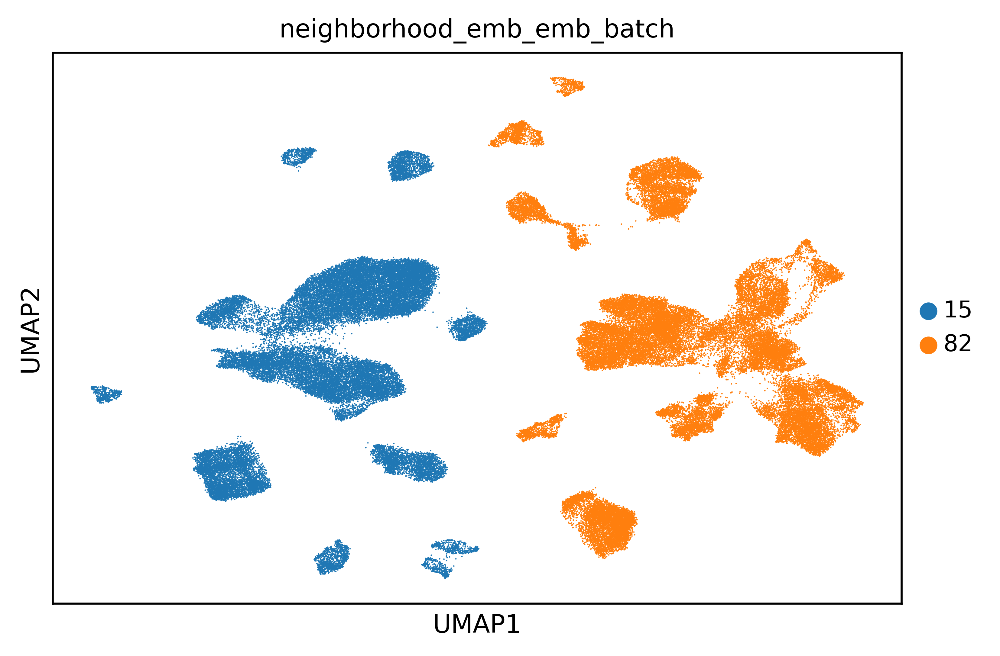

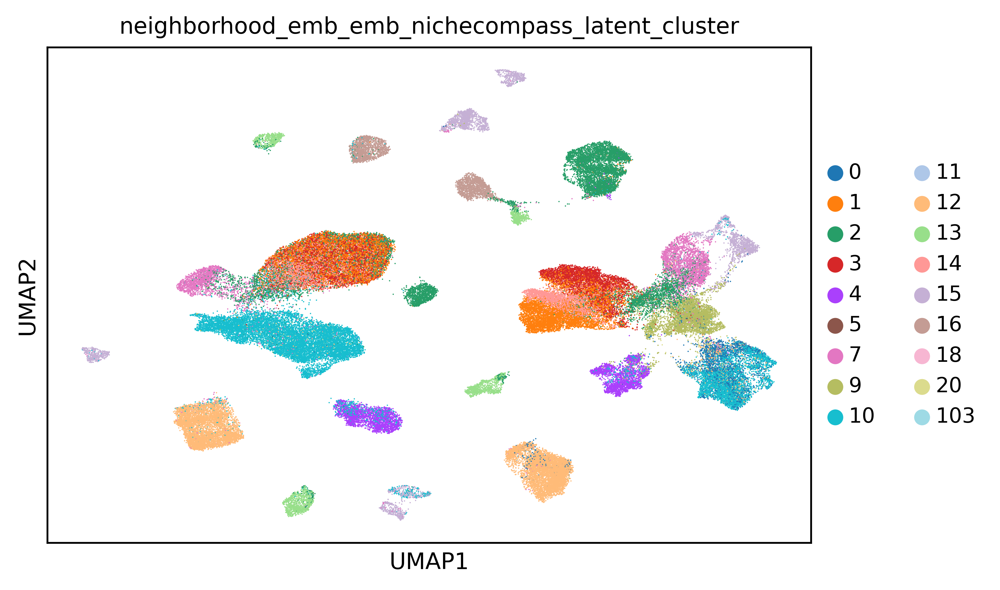

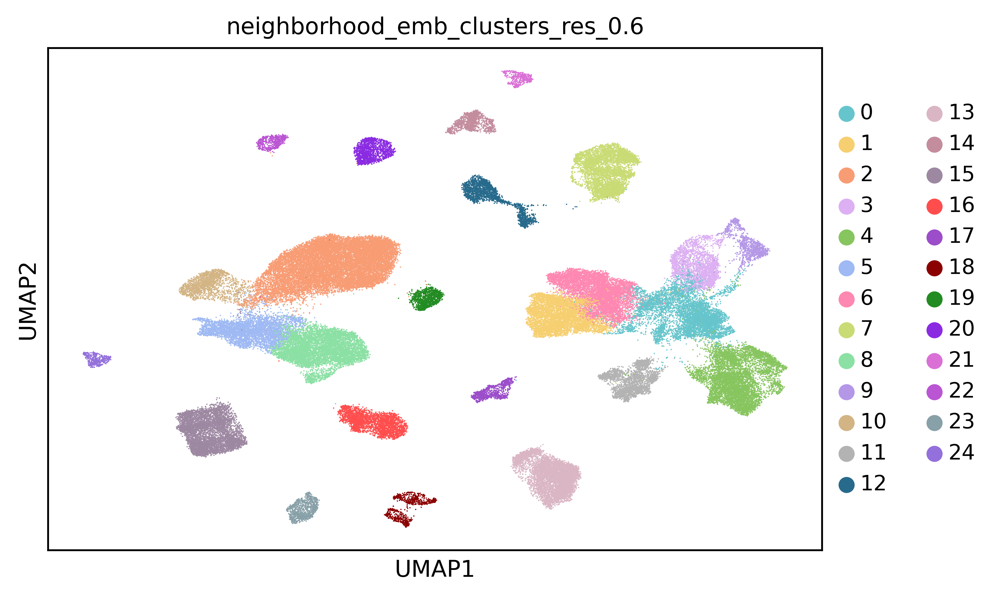

/tmp/ipykernel_2154188/2910531788.py:24: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata_batch,
/nfs/team361/sb75/ENVS/rapids-singlecell-nichejepa/lib/python3.13/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


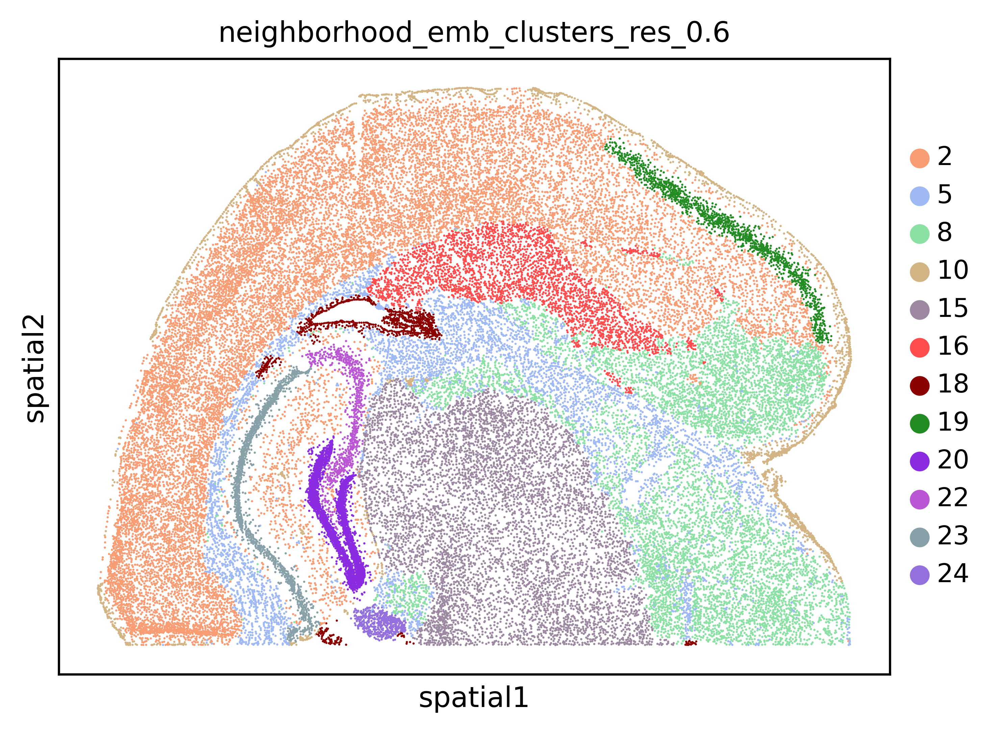

/tmp/ipykernel_2154188/2910531788.py:24: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata_batch,
/nfs/team361/sb75/ENVS/rapids-singlecell-nichejepa/lib/python3.13/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


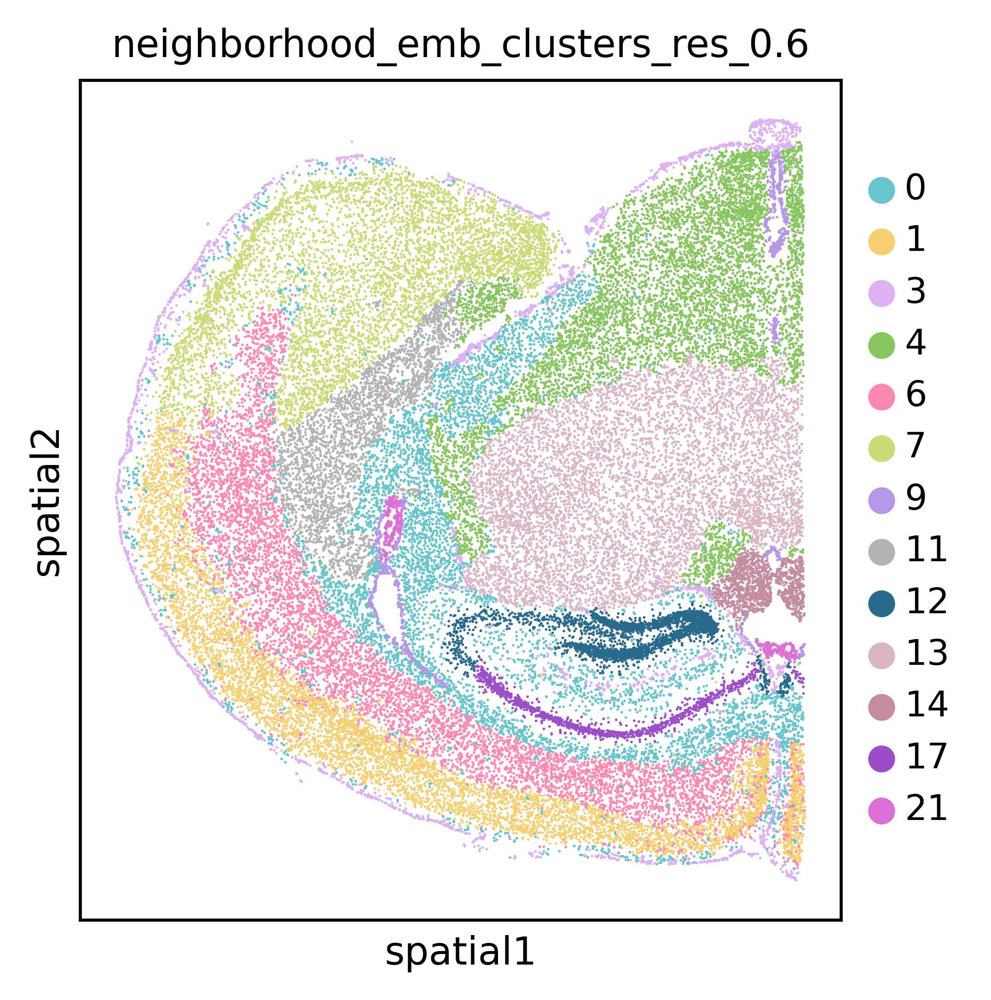

In [53]:
import numpy as np
import matplotlib.pyplot as plt
# Plot UMAPs
#os.makedirs(f'{folder_path}/figures', exist_ok=True)
labels = ['batch', obs_col, latent_cluster_key]
# Plot (aggregated) neighborhood gene embeddings, colored by labels
for label in labels:
    if len(np.unique(adata.obs[label])) > 1:
        sc.pl.umap(adata,
                   neighbors_key=emb_key,
                   title=(emb_key + "_emb_" + label if emb_key not in label else label),
                   color=label,
                   palette=(custom_palette if label == latent_cluster_key else None),
                   show=False)
        plt.show()
        #plt.savefig(f'{folder_path}/figures/{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}{"_" + emb_key + "_emb" if emb_key not in label else ""}_{label}_umap.svg',
        #            dpi=300,
        #            bbox_inches='tight')

# Plot niches in tissue
batch_ids = adata.obs['batch'].unique().tolist()
for i, batch_id in enumerate(batch_ids):
    adata_batch = adata[adata.obs['batch'] == batch_id]
    sc.pl.spatial(adata_batch,
                  color=latent_cluster_key,
                  palette=custom_palette,
                  spot_size=spot_sizes[i],
                  save=f'{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}_{latent_cluster_key}_batch_{batch_id}.svg'
                 )
    os.rename(f'{folder_path}/figures/show{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}_{latent_cluster_key}_batch_{batch_id}.svg',
              f'{folder_path}/figures/{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}_{latent_cluster_key}_batch_{batch_id}.svg'.replace("show", ""))

#if write_to_disk:
    # Save adata
    #adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}.h5ad')


In [54]:
from sklearn.metrics.cluster import adjusted_rand_score, normalized_mutual_info_score
labels = adata.obs[obs_col]
labels_pred = adata.obs[latent_cluster_key]
nmi = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
ari = adjusted_rand_score(labels, labels_pred)
print(f'NMI is {nmi}. ARI is {ari}.')
metrics_df = pd.DataFrame({
    'metric': ['NMI', 'ARI'],
    'value': [nmi, ari]
})

NMI is 0.6415717820495598. ARI is 0.38394660421935217.


In [55]:
import numpy as np

X = adata.obsm[f'neighborhood_emb_layer_{layer}']  # shape (N, D)

# Normalize rows
X_norm = X / np.linalg.norm(X, axis=1, keepdims=True)

# Compute and normalize mean vector
mean_vec = X.mean(axis=0, keepdims=True)
mean_norm = mean_vec / np.linalg.norm(mean_vec)

# Row-wise cosine similarity
cos_sim = (X_norm * mean_norm).sum(axis=1)

# Average
mean_cos = cos_sim.mean()

print(mean_cos)

0.71962255


In [351]:
n_neighbors = 15
emb_key = 'cell_emb'
emb_layer = f'{emb_key}_layer_{layer}'
latent_leiden_resolution = 0.6
latent_cluster_key = f"{emb_key}_clusters_res_{latent_leiden_resolution}"

In [352]:
rsc.pp.neighbors(
    adata,
    n_neighbors=n_neighbors,
    use_rep=emb_layer,
    n_pcs=None,
    key_added=emb_key)

rsc.tl.umap(adata,
            neighbors_key=emb_key,
            key_added=f'{emb_key}_umap')

In [353]:
rsc.tl.leiden(adata,
              neighbors_key=emb_key,
              key_added=latent_cluster_key,
              resolution=latent_leiden_resolution)

In [354]:
obs_col = 'nichecompass_latent_cluster'
adata.obsm['X_umap'] = adata.obsm[f'{emb_key}_umap']

In [355]:
spot_sizes = [100, 20, 20]

In [356]:
import sys
sys.path.append("../../utils")
from analysis_utils import *

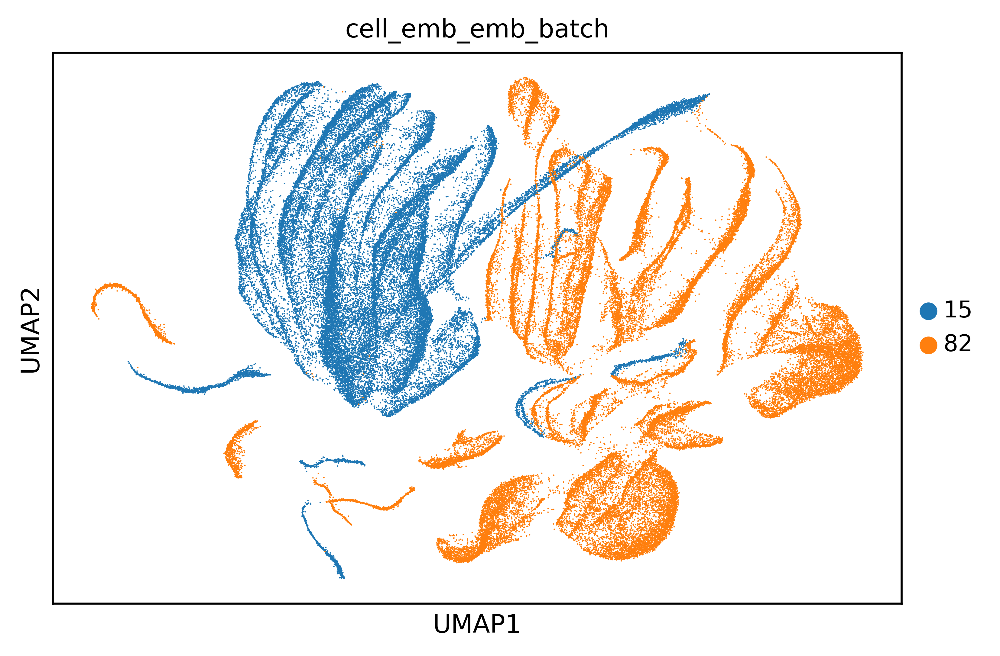

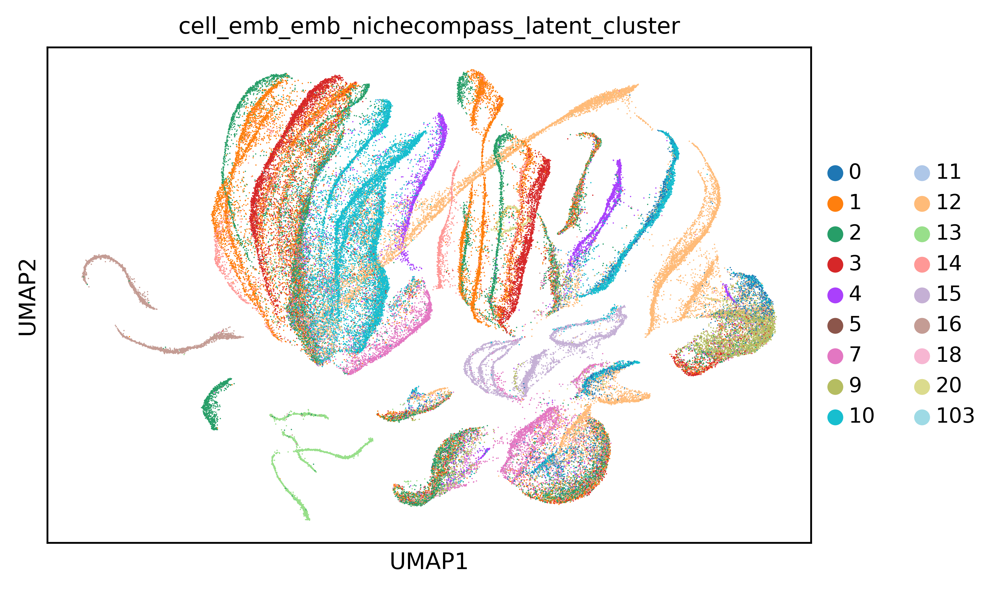

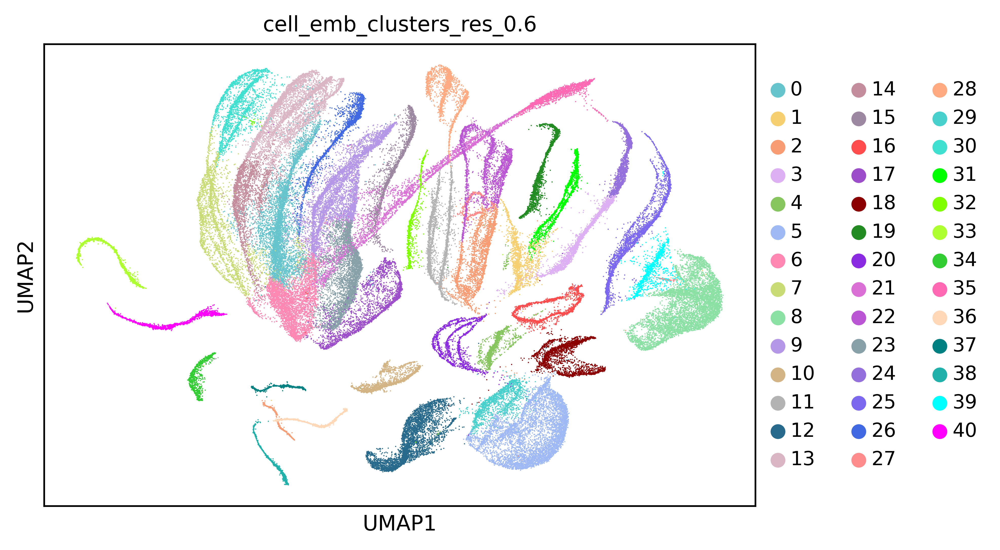

/tmp/ipykernel_1668551/661276689.py:24: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata_batch,
/nfs/team361/sb75/ENVS/rapids-singlecell-nichejepa/lib/python3.13/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


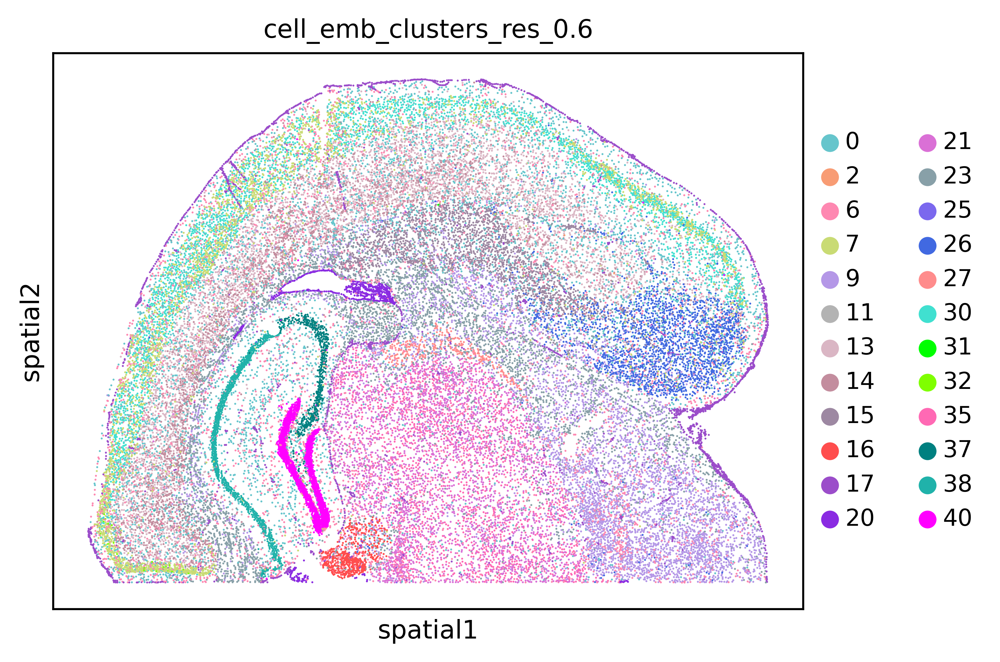

/tmp/ipykernel_1668551/661276689.py:24: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata_batch,
/nfs/team361/sb75/ENVS/rapids-singlecell-nichejepa/lib/python3.13/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


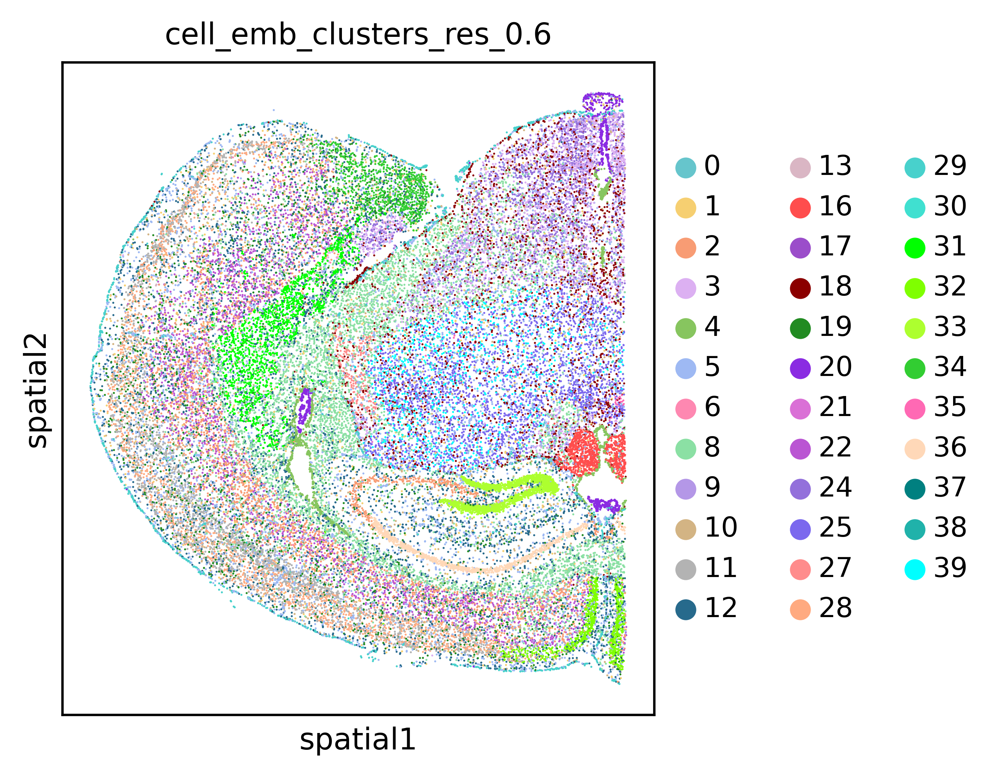

In [357]:
import numpy as np
import matplotlib.pyplot as plt
# Plot UMAPs
#os.makedirs(f'{folder_path}/figures', exist_ok=True)
labels = ['batch', obs_col, latent_cluster_key]
# Plot (aggregated) neighborhood gene embeddings, colored by labels
for label in labels:
    if len(np.unique(adata.obs[label])) > 1:
        sc.pl.umap(adata,
                   neighbors_key=emb_key,
                   title=(emb_key + "_emb_" + label if emb_key not in label else label),
                   color=label,
                   palette=(custom_palette if label == latent_cluster_key else None),
                   show=False)
        plt.show()
        #plt.savefig(f'{folder_path}/figures/{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}{"_" + emb_key + "_emb" if emb_key not in label else ""}_{label}_umap.svg',
        #            dpi=300,
        #            bbox_inches='tight')

# Plot niches in tissue
batch_ids = adata.obs['batch'].unique().tolist()
for i, batch_id in enumerate(batch_ids):
    adata_batch = adata[adata.obs['batch'] == batch_id]
    sc.pl.spatial(adata_batch,
                  color=latent_cluster_key,
                  palette=custom_palette,
                  spot_size=spot_sizes[i],
                  #save=f'{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}_{latent_cluster_key}_batch_{batch_id}.svg'
                 )
    #os.rename(f'{folder_path}/figures/show{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}_{latent_cluster_key}_batch_{batch_id}.svg',
    #          f'{folder_path}/figures/{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}_{latent_cluster_key}_batch_{batch_id}.svg'.replace("show", ""))

#if write_to_disk:
    # Save adata
    #adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}.h5ad')


In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=min(Z.shape[0], Z.shape[1]))
pca.fit(Z)

explained = pca.explained_variance_ratio_
print("Cumulative variance first 10 dims:", explained[:10].sum())


In [ ]:
import numpy as np

eigvals = pca.explained_variance_
eigvals = eigvals[eigvals > 0]  # remove zeros

p = eigvals / eigvals.sum()
effective_rank = np.exp(-(p * np.log(p)).sum())
print("Effective rank:", effective_rank)
